In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("skimage") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-image"], check=True)

import hashlib
import json
import math
import os
import platform
import random
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skimage
import torch
import torch.nn as nn
import torchvision
from skimage.metrics import structural_similarity
from torch.utils.data import ConcatDataset, DataLoader, Subset
from torchvision import datasets, transforms

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HARDWARE = torch.cuda.get_device_name(0) if torch.cuda.is_available() else (platform.processor() or platform.machine() or "CPU")

RUNTIME_VERSIONS = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "scikit_image": skimage.__version__,
    "matplotlib": matplotlib.__version__,
    "pandas": pd.__version__,
    "cuda": torch.version.cuda if torch.cuda.is_available() else None,
    "cudnn": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
}
print("Device:", DEVICE, "|", HARDWARE)
print(json.dumps(RUNTIME_VERSIONS, indent=2))

Device: cuda | Tesla T4
{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "numpy": "2.4.6",
  "scikit_image": "0.25.2",
  "matplotlib": "3.10.0",
  "pandas": "2.2.3",
  "cuda": "13.0",
  "cudnn": 92800
}


In [2]:
SEED = 42
MODEL_NAME = "02_sparse_ae"
MODEL_CLASS = "SparseAutoencoder"
INPUT_DIM = 28 * 28
HIDDEN_DIM = 256
LATENT_DIM = 64
EXPECTED_TRAINABLE_PARAMS = 435_536
BATCH_SIZE = 128
NUM_WORKERS = 2
LEARNING_RATE = 1e-3
NUM_EPOCHS = 30
LAMBDA_L1 = 0.001
SPARSITY_THRESHOLD = 1e-8
NUM_CLASSES = 10
TRAIN_PER_CLASS, VAL_PER_CLASS, TEST_PER_CLASS = 5600, 700, 700
SSIM_PARAMS = {"data_range": 1.0, "gaussian_weights": True, "sigma": 1.5,
               "win_size": 11, "use_sample_covariance": False}
LATENCY_BATCH_SIZE = 64
LATENCY_WARMUP_RUNS = 20
LATENCY_TIMED_RUNS = 100
INTERPOLATION_ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

from google.colab import drive
drive.mount("/content/drive")

ROOT_DIR = "/content/drive/MyDrive/generative-model-comparison/02_sparse_ae"
DATA_DIR = os.path.join(ROOT_DIR, "data", "fashion_mnist")
RESULTS_DIR = os.path.join(ROOT_DIR, "results")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")
for directory in (DATA_DIR, RESULTS_DIR, FIGURES_DIR):
    os.makedirs(directory, exist_ok=True)

PATHS = {
    "best_model": os.path.join(RESULTS_DIR, "best_model.pth"),
    "metrics": os.path.join(RESULTS_DIR, "metrics.json"),
    "training_history": os.path.join(RESULTS_DIR, "training_history.csv"),
    "experiment_config": os.path.join(RESULTS_DIR, "experiment_config.json"),
    "split_report": os.path.join(RESULTS_DIR, "split_report.json"),
    "training_curves": os.path.join(FIGURES_DIR, "training_curves.png"),
    "latent_sparsity_curve": os.path.join(FIGURES_DIR, "latent_sparsity_curve.png"),
    "reconstruction_comparison": os.path.join(FIGURES_DIR, "reconstruction_comparison.png"),
    "latent_interpolation": os.path.join(FIGURES_DIR, "latent_interpolation.png"),
}

CONFIG = {
    "model_name": MODEL_NAME,
    "model_class": MODEL_CLASS,
    "seed": SEED,
    "dataset": "Fashion-MNIST (torchvision train=True 60000 + train=False 10000, pooled in that order)",
    "preprocessing": "transforms.ToTensor() only; [1, 28, 28]; values in [0, 1]",
    "split": {"method": "class-stratified 80/10/10, np.random.default_rng(42)",
              "train_per_class": TRAIN_PER_CLASS, "val_per_class": VAL_PER_CLASS,
              "test_per_class": TEST_PER_CLASS, "train_total": 56000, "val_total": 7000, "test_total": 7000},
    "architecture": {
        "encoder": "Flatten(784) -> Linear(784,256) -> ReLU -> Linear(256,64) -> ReLU",
        "decoder": "Linear(64,256) -> ReLU -> Linear(256,784) -> Sigmoid -> reshape [B,1,28,28]",
        "input_dim": INPUT_DIM, "hidden_dim": HIDDEN_DIM, "latent_dim": LATENT_DIM,
        "expected_trainable_params": EXPECTED_TRAINABLE_PARAMS,
    },
    "objective": {
        "reconstruction_loss": "nn.MSELoss(reduction='mean')",
        "raw_l1": "latent.abs().mean() over batch and all 64 latent dims",
        "lambda_l1": LAMBDA_L1,
        "total": "reconstruction_mse + lambda_l1 * latent.abs().mean()",
    },
    "sparsity_threshold": SPARSITY_THRESHOLD,
    "optimizer": {"name": "Adam", "lr": LEARNING_RATE, "betas": [0.9, 0.999], "eps": 1e-8, "weight_decay": 0.0},
    "epochs": NUM_EPOCHS,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": bool(torch.cuda.is_available()),
    "train_loader_generator_seed": SEED,
    "regularization_other": "none (no early stopping, scheduler, clipping, mixed precision, dropout, batchnorm)",
    "model_selection": "lowest validation reconstruction MSE",
    "ssim_params": SSIM_PARAMS,
    "latency": {"batch_size": LATENCY_BATCH_SIZE, "warmup_runs": LATENCY_WARMUP_RUNS, "timed_runs": LATENCY_TIMED_RUNS, "definition": "encoder + decoder forward pass",},
    "interpolation_alphas": INTERPOLATION_ALPHAS,
    "root_dir": ROOT_DIR,
    "data_dir": DATA_DIR,
    "results_dir": RESULTS_DIR,
}

def write_json(path, obj):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, allow_nan=False)

write_json(PATHS["experiment_config"], CONFIG)
print("Results directory:", RESULTS_DIR)

Mounted at /content/drive
Results directory: /content/drive/MyDrive/generative-model-comparison/02_sparse_ae/results


In [3]:
transform = transforms.ToTensor()
fashion_train = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True, transform=transform)
fashion_test = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True, transform=transform)
assert len(fashion_train) == 60000 and len(fashion_test) == 10000

pooled_dataset = ConcatDataset([fashion_train, fashion_test])
assert len(pooled_dataset) == 70000

labels = np.concatenate([fashion_train.targets.numpy().astype(np.int64),
                         fashion_test.targets.numpy().astype(np.int64)])
rng = np.random.default_rng(SEED)
train_parts, val_parts, test_parts = [], [], []
for class_id in range(NUM_CLASSES):
    class_indices = np.flatnonzero(labels == class_id).copy()
    rng.shuffle(class_indices)
    train_parts.append(class_indices[:5600])
    val_parts.append(class_indices[5600:6300])
    test_parts.append(class_indices[6300:])
train_indices = np.concatenate(train_parts).astype(np.int64)
val_indices = np.concatenate(val_parts).astype(np.int64)
test_indices = np.concatenate(test_parts).astype(np.int64)
rng.shuffle(train_indices)
rng.shuffle(val_indices)
rng.shuffle(test_indices)

def sha256_of_indices(indices):
    return hashlib.sha256(np.ascontiguousarray(indices, dtype=np.int64).tobytes()).hexdigest()

def per_class_counts(indices):
    return {str(c): int(n) for c, n in enumerate(np.bincount(labels[indices], minlength=NUM_CLASSES))}

assert len(train_indices) == 56000 and len(val_indices) == 7000 and len(test_indices) == 7000
for name, idx, per_class in (("train", train_indices, TRAIN_PER_CLASS), ("val", val_indices, VAL_PER_CLASS),
                             ("test", test_indices, TEST_PER_CLASS)):
    assert idx.dtype == np.int64
    assert len(np.unique(idx)) == len(idx), f"duplicates in {name}"
    assert all(v == per_class for v in per_class_counts(idx).values()), f"bad per-class counts in {name}"
assert len(np.intersect1d(train_indices, val_indices)) == 0
assert len(np.intersect1d(train_indices, test_indices)) == 0
assert len(np.intersect1d(val_indices, test_indices)) == 0
assert np.array_equal(np.sort(np.concatenate([train_indices, val_indices, test_indices])), np.arange(70000))

SPLIT_REPORT = {
    "seed": SEED,
    "pooled_total": 70000,
    "counts": {"train": int(len(train_indices)), "val": int(len(val_indices)), "test": int(len(test_indices))},
    "per_class_counts": {"train": per_class_counts(train_indices), "val": per_class_counts(val_indices),
                         "test": per_class_counts(test_indices)},
    "sha256": {"train": sha256_of_indices(train_indices), "val": sha256_of_indices(val_indices),
               "test": sha256_of_indices(test_indices)},
    "hash_method": "hashlib.sha256(np.ascontiguousarray(indices, dtype=np.int64).tobytes())",
}

MODEL01_SPLIT_REPORT_PATH = (
    "/content/drive/MyDrive/generative-model-comparison/"
    "01_vanilla_ae/results/split_report.json"
)
assert os.path.isfile(MODEL01_SPLIT_REPORT_PATH), (
    "Model 01 must be completed first. "
    "Canonical split_report.json was not found."
)
with open(MODEL01_SPLIT_REPORT_PATH, "r") as f:
    model01_hashes = json.load(f)["index_sha256_int64"]
expected_hashes = {
    "train": model01_hashes["train"],
    "val": model01_hashes["validation"],
    "test": model01_hashes["test"],
}
assert SPLIT_REPORT["sha256"] == expected_hashes, (
    "Model 02 split does not match Model 01!\n"
    f"Model 02: {SPLIT_REPORT['sha256']}\n"
    f"Model 01: {expected_hashes}"
)

print("PASS: Model 02 split hashes match Model 01 exactly.")
write_json(PATHS["split_report"], SPLIT_REPORT)
print(json.dumps(SPLIT_REPORT["counts"]), "\n", json.dumps(SPLIT_REPORT["sha256"], indent=2))

PASS: Model 02 split hashes match Model 01 exactly.
{"train": 56000, "val": 7000, "test": 7000} 
 {
  "train": "33ea53524b4322bff6a3800d5f997fb49a2c3109cc676bcec3f5bd75614d563f",
  "val": "ec0ca9f1abc64ba260835d8b8ade0d19c59aed038153fbab1103386380698254",
  "test": "e10a9ab4471795dfab37b6b9a652c9a27f56343cea3a08bb82b97de2332bc3a1"
}


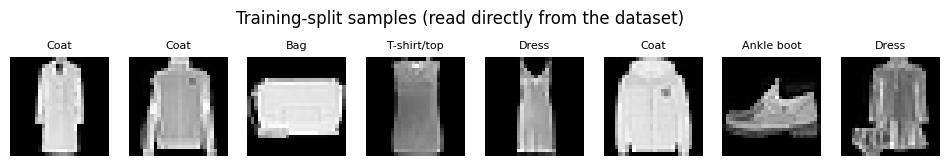

Batches per epoch: train=438, val=55, test=55


In [4]:
PIN_MEMORY = torch.cuda.is_available()
train_dataset = Subset(pooled_dataset, train_indices.tolist())
val_dataset = Subset(pooled_dataset, val_indices.tolist())
test_dataset = Subset(pooled_dataset, test_indices.tolist())

train_generator = torch.Generator()
train_generator.manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=train_generator,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for pos, ax in enumerate(axes):
    image, label = train_dataset[pos]
    assert image.shape == (1, 28, 28) and image.dtype == torch.float32
    assert 0.0 <= image.min().item() and image.max().item() <= 1.0
    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[label], fontsize=8)
    ax.axis("off")
plt.suptitle("Training-split samples (read directly from the dataset)")
plt.show()
print(f"Batches per epoch: train={len(train_loader)}, val={len(val_loader)}, test={len(test_loader)}")

In [5]:
class SparseAutoencoder(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid(),
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        latent = self.encode(x)
        return self.decode(latent), latent


torch.manual_seed(SEED)
model = SparseAutoencoder().to(DEVICE)
TRAINABLE_PARAMS = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print("Trainable parameters:", TRAINABLE_PARAMS)
assert TRAINABLE_PARAMS == EXPECTED_TRAINABLE_PARAMS

with torch.no_grad():
    probe = torch.stack([val_dataset[i][0] for i in range(4)]).to(DEVICE)
    probe_recon, probe_latent = model(probe)
assert probe_recon.shape == (4, 1, 28, 28)
assert probe_latent.shape == (4, LATENT_DIM)
assert torch.all(probe_latent >= 0), "ReLU latent must be non-negative"
assert torch.all((probe_recon >= 0) & (probe_recon <= 1)), "Sigmoid output must lie in [0, 1]"
print("Architecture, output and latent assertions passed.")

SparseAutoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Trainable parameters: 435536
Architecture, output and latent assertions passed.


In [6]:
criterion = nn.MSELoss(reduction="mean")
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)


def cuda_sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def run_epoch(loader, train):
    model.train(train)
    sums = {"mse": 0.0, "l1_raw": 0.0, "total": 0.0}
    num_samples, zero_count, latent_count = 0, 0, 0
    with torch.set_grad_enabled(train):
        for images, _ in loader:
            images = images.to(DEVICE, non_blocking=True)
            recon, latent = model(images)
            mse = criterion(recon, images)
            l1_raw = latent.abs().mean()
            total = mse + LAMBDA_L1 * l1_raw
            if train:
                optimizer.zero_grad()
                total.backward()
                optimizer.step()
            batch_size = images.size(0)
            sums["mse"] += mse.item() * batch_size
            sums["l1_raw"] += l1_raw.item() * batch_size
            sums["total"] += total.item() * batch_size
            zero_count += int((latent.detach() <= SPARSITY_THRESHOLD).sum().item())
            latent_count += latent.numel()
            num_samples += batch_size
    l1_raw_mean = sums["l1_raw"] / num_samples
    return {"recon_mse": sums["mse"] / num_samples,
            "l1_raw": l1_raw_mean,
            "l1_weighted": LAMBDA_L1 * l1_raw_mean,
            "total_objective": sums["total"] / num_samples,
            "zero_fraction": zero_count / latent_count}


history = []
best_val_mse = float("inf")
best_val_total = None
best_epoch = None

training_start = time.perf_counter()
for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.perf_counter()

    cuda_sync(); t0 = time.perf_counter()
    train_stats = run_epoch(train_loader, train=True)
    cuda_sync(); train_time = time.perf_counter() - t0

    cuda_sync(); t0 = time.perf_counter()
    val_stats = run_epoch(val_loader, train=False)
    cuda_sync(); val_time = time.perf_counter() - t0

    is_best = val_stats["recon_mse"] < best_val_mse
    if is_best:
        best_val_mse = val_stats["recon_mse"]
        best_val_total = val_stats["total_objective"]
        best_epoch = epoch
        torch.save({
            "model_state_dict": model.state_dict(),
            "model_name": MODEL_NAME,
            "model_class": MODEL_CLASS,
            "best_epoch": best_epoch,
            "best_val_recon_mse": float(best_val_mse),
            "best_val_total_objective": float(best_val_total),
            "latent_dim": LATENT_DIM,
            "lambda_l1": LAMBDA_L1,
            "sparsity_threshold": SPARSITY_THRESHOLD,
            "trainable_params": TRAINABLE_PARAMS,
            "config": CONFIG,
        }, PATHS["best_model"])

    epoch_wall_time = time.perf_counter() - epoch_start

    row = {"epoch": epoch}
    for key, value in train_stats.items():
        row[f"train_{key}"] = value
    for key, value in val_stats.items():
        row[f"val_{key}"] = value
    row.update({"train_time_s": train_time, "val_time_s": val_time,
                "epoch_wall_time_s": epoch_wall_time, "is_best": bool(is_best)})
    history.append(row)
    pd.DataFrame(history).to_csv(PATHS["training_history"], index=False)

    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | train MSE {train_stats['recon_mse']:.6f} "
          f"total {train_stats['total_objective']:.6f} zero {train_stats['zero_fraction']:.3f} | "
          f"val MSE {val_stats['recon_mse']:.6f} total {val_stats['total_objective']:.6f} "
          f"zero {val_stats['zero_fraction']:.3f} | {epoch_wall_time:.1f}s{'  *best*' if is_best else ''}")

TOTAL_TRAINING_WALL_TIME = time.perf_counter() - training_start
history_df = pd.DataFrame(history)
assert len(history_df) == NUM_EPOCHS
print(f"\nBest epoch {best_epoch}: val MSE {best_val_mse:.6f}, val total {best_val_total:.6f}")
print(f"Total training wall time: {TOTAL_TRAINING_WALL_TIME:.1f}s")

Epoch 01/30 | train MSE 0.035008 total 0.036028 zero 0.571 | val MSE 0.019708 total 0.020576 zero 0.545 | 9.4s  *best*
Epoch 02/30 | train MSE 0.017662 total 0.018461 zero 0.536 | val MSE 0.015724 total 0.016483 zero 0.520 | 8.9s  *best*
Epoch 03/30 | train MSE 0.014976 total 0.015718 zero 0.511 | val MSE 0.014022 total 0.014735 zero 0.506 | 7.5s  *best*
Epoch 04/30 | train MSE 0.013526 total 0.014233 zero 0.496 | val MSE 0.012763 total 0.013465 zero 0.488 | 8.6s  *best*
Epoch 05/30 | train MSE 0.012469 total 0.013157 zero 0.481 | val MSE 0.011913 total 0.012584 zero 0.475 | 8.3s  *best*
Epoch 06/30 | train MSE 0.011691 total 0.012364 zero 0.470 | val MSE 0.011299 total 0.011968 zero 0.465 | 8.5s  *best*
Epoch 07/30 | train MSE 0.011136 total 0.011793 zero 0.463 | val MSE 0.010934 total 0.011580 zero 0.461 | 8.0s  *best*
Epoch 08/30 | train MSE 0.010705 total 0.011348 zero 0.458 | val MSE 0.010538 total 0.011183 zero 0.453 | 7.4s  *best*
Epoch 09/30 | train MSE 0.010374 total 0.011003 

Loaded best checkpoint from epoch 30 (val MSE 0.008219, val total 0.008675)


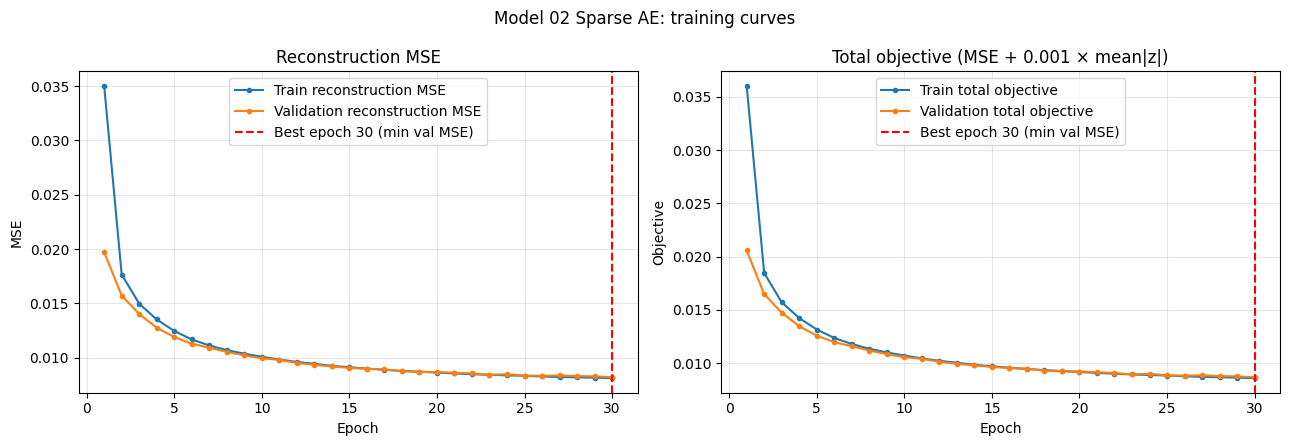

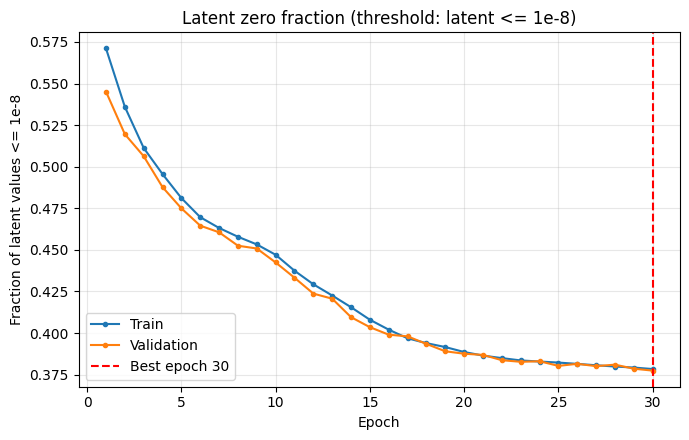

In [7]:
checkpoint = torch.load(PATHS["best_model"], map_location=DEVICE, weights_only=True)
model = SparseAutoencoder().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
assert checkpoint["best_epoch"] == best_epoch
assert checkpoint["trainable_params"] == EXPECTED_TRAINABLE_PARAMS
print(f"Loaded best checkpoint from epoch {checkpoint['best_epoch']} "
      f"(val MSE {checkpoint['best_val_recon_mse']:.6f}, val total {checkpoint['best_val_total_objective']:.6f})")

epochs = history_df["epoch"].to_numpy()

fig, (ax_mse, ax_total) = plt.subplots(1, 2, figsize=(13, 4.5))
ax_mse.plot(epochs, history_df["train_recon_mse"], marker="o", ms=3, label="Train reconstruction MSE")
ax_mse.plot(epochs, history_df["val_recon_mse"], marker="o", ms=3, label="Validation reconstruction MSE")
ax_mse.set_title("Reconstruction MSE")
ax_mse.set_ylabel("MSE")
ax_total.plot(epochs, history_df["train_total_objective"], marker="o", ms=3, label="Train total objective")
ax_total.plot(epochs, history_df["val_total_objective"], marker="o", ms=3, label="Validation total objective")
ax_total.set_title(f"Total objective (MSE + {LAMBDA_L1} × mean|z|)")
ax_total.set_ylabel("Objective")
for ax in (ax_mse, ax_total):
    ax.axvline(best_epoch, color="red", linestyle="--", label=f"Best epoch {best_epoch} (min val MSE)")
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Model 02 Sparse AE: training curves")
fig.tight_layout()
fig.savefig(PATHS["training_curves"], dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(epochs, history_df["train_zero_fraction"], marker="o", ms=3, label="Train")
ax.plot(epochs, history_df["val_zero_fraction"], marker="o", ms=3, label="Validation")
ax.axvline(best_epoch, color="red", linestyle="--", label=f"Best epoch {best_epoch}")
ax.set_xlabel("Epoch")
ax.set_ylabel("Fraction of latent values <= 1e-8")
ax.set_title("Latent zero fraction (threshold: latent <= 1e-8)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(PATHS["latent_sparsity_curve"], dpi=150, bbox_inches="tight")
plt.show()

In [8]:
squared_error_sum = 0.0
pixel_count = 0
latent_abs_sum = 0.0
latent_zero_count = 0
latent_element_count = 0
originals_list, recons_list = [], []

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        recon, latent = model(images)
        squared_error_sum += ((recon.double() - images.double()) ** 2).sum().item()
        pixel_count += images.numel()
        latent_abs_sum += latent.double().abs().sum().item()
        latent_zero_count += int((latent <= SPARSITY_THRESHOLD).sum().item())
        latent_element_count += latent.numel()
        originals_list.append(images.cpu().numpy())
        recons_list.append(recon.cpu().numpy())

test_originals = np.concatenate(originals_list)[:, 0].astype(np.float64)
test_recons = np.concatenate(recons_list)[:, 0].astype(np.float64)
assert test_originals.shape == (7000, 28, 28) and pixel_count == 7000 * 784

test_mse = squared_error_sum / pixel_count
test_psnr = float("inf") if test_mse == 0 else 10.0 * math.log10(1.0 / test_mse)

ssim_values = np.array([structural_similarity(test_originals[i], test_recons[i], **SSIM_PARAMS)
                        for i in range(len(test_originals))])
assert len(ssim_values) == 7000
test_ssim = float(ssim_values.mean())

test_l1_raw = latent_abs_sum / latent_element_count
test_zero_fraction = latent_zero_count / latent_element_count
TEST_SPARSITY = {
    "mean_abs_latent_activation": test_l1_raw,
    "weighted_l1_penalty": LAMBDA_L1 * test_l1_raw,
    "zero_fraction_le_threshold": test_zero_fraction,
    "active_fraction_gt_threshold": (latent_element_count - latent_zero_count) / latent_element_count,
    "threshold": SPARSITY_THRESHOLD,
    "num_latent_elements": latent_element_count,
}
print(f"Test MSE:  {test_mse:.6f}")
print(f"Test PSNR: {test_psnr:.4f} dB")
print(f"Test SSIM: {test_ssim:.4f} (mean of {len(ssim_values)} images)")
print("Test latent sparsity diagnostics (not reconstruction-quality metrics):")
print(json.dumps(TEST_SPARSITY, indent=2))

Test MSE:  0.008382
Test PSNR: 20.7667 dB
Test SSIM: 0.7405 (mean of 7000 images)
Test latent sparsity diagnostics (not reconstruction-quality metrics):
{
  "mean_abs_latent_activation": 0.45641116000921983,
  "weighted_l1_penalty": 0.00045641116000921984,
  "zero_fraction_le_threshold": 0.37774107142857144,
  "active_fraction_gt_threshold": 0.6222589285714286,
  "threshold": 1e-08,
  "num_latent_elements": 448000
}


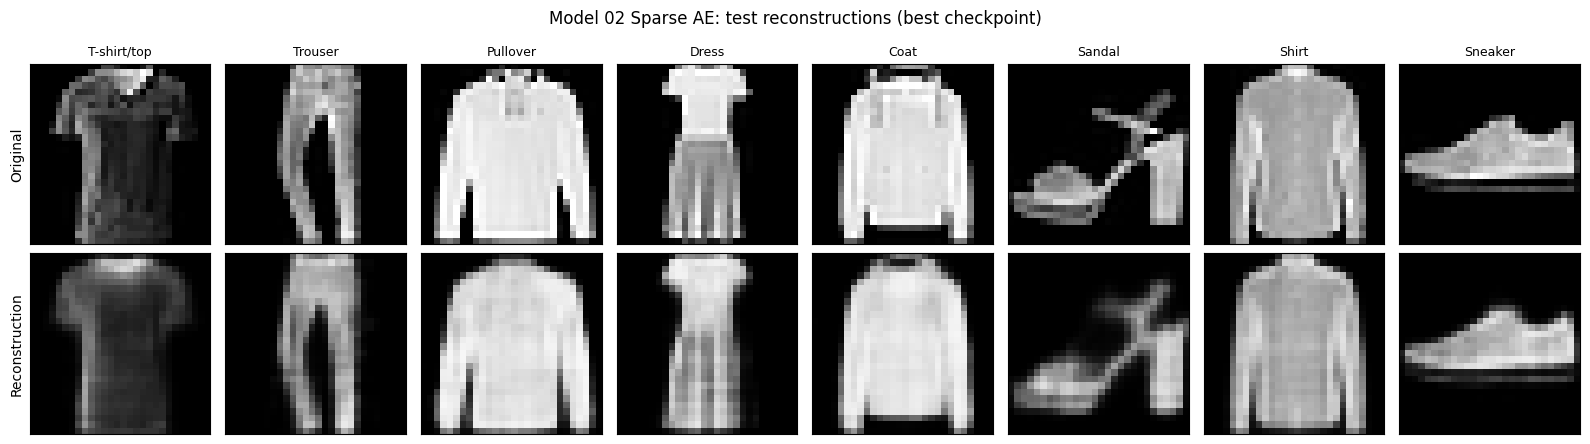

In [9]:
test_labels = labels[test_indices]
first_test_position = {c: int(np.flatnonzero(test_labels == c)[0]) for c in range(NUM_CLASSES)}
RECON_SAMPLES = [{"class_id": c, "class_name": CLASS_NAMES[c], "test_position": first_test_position[c],
                  "pooled_index": int(test_indices[first_test_position[c]])} for c in range(8)]

fig, axes = plt.subplots(2, len(RECON_SAMPLES), figsize=(2 * len(RECON_SAMPLES), 4.6))
with torch.no_grad():
    for col, sample in enumerate(RECON_SAMPLES):
        image, label = pooled_dataset[sample["pooled_index"]]
        assert label == sample["class_id"]
        recon, _ = model(image.unsqueeze(0).to(DEVICE))
        axes[0, col].imshow(image.squeeze().numpy(), cmap="gray", vmin=0, vmax=1)
        axes[0, col].set_title(sample["class_name"], fontsize=9)
        axes[1, col].imshow(recon.squeeze().cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        for row in range(2):
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruction")
fig.suptitle("Model 02 Sparse AE: test reconstructions (best checkpoint)")
fig.tight_layout()
fig.savefig(PATHS["reconstruction_comparison"], dpi=150, bbox_inches="tight")
plt.show()

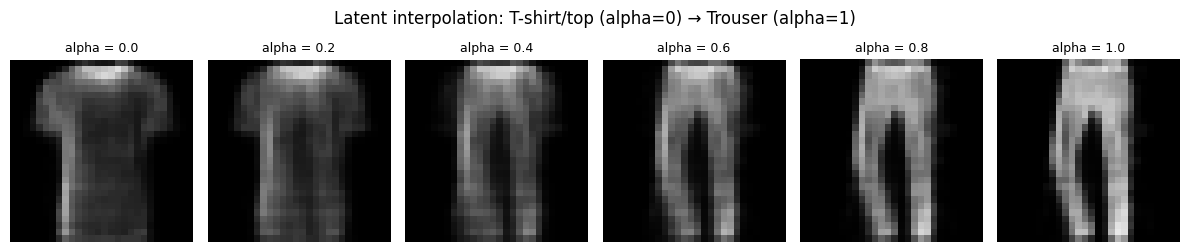

In [10]:
INTERP_ENDPOINTS = {
    "start": {"class_id": 0, "class_name": CLASS_NAMES[0], "test_position": first_test_position[0],
              "pooled_index": int(test_indices[first_test_position[0]])},
    "end": {"class_id": 1, "class_name": CLASS_NAMES[1], "test_position": first_test_position[1],
            "pooled_index": int(test_indices[first_test_position[1]])},
}
start_image, _ = pooled_dataset[INTERP_ENDPOINTS["start"]["pooled_index"]]
end_image, _ = pooled_dataset[INTERP_ENDPOINTS["end"]["pooled_index"]]

fig, axes = plt.subplots(1, len(INTERPOLATION_ALPHAS), figsize=(2 * len(INTERPOLATION_ALPHAS), 2.6))
with torch.no_grad():
    z_start = model.encode(start_image.unsqueeze(0).to(DEVICE))
    z_end = model.encode(end_image.unsqueeze(0).to(DEVICE))
    assert z_start.shape == (1, LATENT_DIM)
    for ax, alpha in zip(axes, INTERPOLATION_ALPHAS):
        decoded = model.decode((1.0 - alpha) * z_start + alpha * z_end)
        ax.imshow(decoded.squeeze().cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"alpha = {alpha:.1f}", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Latent interpolation: {CLASS_NAMES[0]} (alpha=0) → {CLASS_NAMES[1]} (alpha=1)")
fig.tight_layout()
fig.savefig(PATHS["latent_interpolation"], dpi=150, bbox_inches="tight")
plt.show()

In [11]:
model.eval()
latency_input = torch.stack([
    test_dataset[i][0] for i in range(LATENCY_BATCH_SIZE)
]).to(DEVICE)
assert latency_input.shape == (LATENCY_BATCH_SIZE, 1, 28, 28)

latency_runs_ms = []
with torch.inference_mode():
    for _ in range(LATENCY_WARMUP_RUNS):
        _ = model(latency_input)
    cuda_sync()

    for _ in range(LATENCY_TIMED_RUNS):
        cuda_sync()
        t0 = time.perf_counter()
        _ = model(latency_input)
        cuda_sync()
        latency_runs_ms.append((time.perf_counter() - t0) * 1000.0)

latency_runs_ms = np.asarray(latency_runs_ms, dtype=np.float64)
LATENCY = {
    "mean_ms_per_batch": float(latency_runs_ms.mean()),
    "std_ms_per_batch": float(latency_runs_ms.std(ddof=1)),
    "median_ms_per_batch": float(np.median(latency_runs_ms)),
    "ms_per_image": float(latency_runs_ms.mean() / LATENCY_BATCH_SIZE),
    "batch_size": LATENCY_BATCH_SIZE,
    "warmup_runs": LATENCY_WARMUP_RUNS,
    "timed_runs": LATENCY_TIMED_RUNS,
    "device": str(DEVICE),
    "hardware": HARDWARE,
    "definition": "encoder + decoder forward pass",
    "note": "Hardware-dependent; compare only on the same hardware.",
}
print(json.dumps(LATENCY, indent=2))

{
  "mean_ms_per_batch": 0.23055031000239978,
  "std_ms_per_batch": 0.08016862090063935,
  "median_ms_per_batch": 0.21347500000956643,
  "ms_per_image": 0.0036023485937874966,
  "batch_size": 64,
  "warmup_runs": 20,
  "timed_runs": 100,
  "device": "cuda",
  "hardware": "Tesla T4",
  "definition": "encoder + decoder forward pass",
  "note": "Hardware-dependent; compare only on the same hardware."
}


In [12]:
METRICS = {
    "model_name": MODEL_NAME,
    "model_class": MODEL_CLASS,
    "seed": SEED,
    "split_counts": SPLIT_REPORT["counts"],
    "split_per_class_counts": SPLIT_REPORT["per_class_counts"],
    "split_sha256": SPLIT_REPORT["sha256"],
    "epochs_completed": int(len(history_df)),
    "best_epoch": int(best_epoch),
    "best_val_recon_mse": float(best_val_mse),
    "best_val_total_objective": float(best_val_total),
    "model_selection": "lowest validation reconstruction MSE",
    "lambda_l1": LAMBDA_L1,
    "sparsity_threshold": SPARSITY_THRESHOLD,
    "latent_dim": LATENT_DIM,
    "trainable_params": int(TRAINABLE_PARAMS),
    "test": {
        "num_images": int(len(test_originals)),
        "mse": float(test_mse),
        "psnr_db": "inf" if math.isinf(test_psnr) else float(test_psnr),
        "ssim_mean": test_ssim,
        "ssim_num_images": int(len(ssim_values)),
        "ssim_params": SSIM_PARAMS,
        "ssim_implementation": "skimage.metrics.structural_similarity, arithmetic mean over images",
        "latent_sparsity": TEST_SPARSITY,
    },
    "timing": {
        "total_training_wall_time_s": float(TOTAL_TRAINING_WALL_TIME),
        "mean_epoch_wall_time_s": float(history_df["epoch_wall_time_s"].mean()),
        "total_epoch_wall_time_s": float(history_df["epoch_wall_time_s"].sum()),
        "mean_train_time_s": float(history_df["train_time_s"].mean()),
        "mean_val_time_s": float(history_df["val_time_s"].mean()),
    },
    "latency": LATENCY,
    "runtime_versions": RUNTIME_VERSIONS,
    "figure_samples": {
        "reconstruction_comparison": RECON_SAMPLES,
        "latent_interpolation": {"endpoints": INTERP_ENDPOINTS, "alphas": INTERPOLATION_ALPHAS},
    },
    "artifacts": PATHS,
}

write_json(PATHS["metrics"], METRICS)
write_json(PATHS["experiment_config"], CONFIG)
write_json(PATHS["split_report"], SPLIT_REPORT)
history_df.to_csv(PATHS["training_history"], index=False)

for name, path in PATHS.items():
    print(f"{name:28s} {path}")

best_model                   /content/drive/MyDrive/generative-model-comparison/02_sparse_ae/results/best_model.pth
metrics                      /content/drive/MyDrive/generative-model-comparison/02_sparse_ae/results/metrics.json
training_history             /content/drive/MyDrive/generative-model-comparison/02_sparse_ae/results/training_history.csv
experiment_config            /content/drive/MyDrive/generative-model-comparison/02_sparse_ae/results/experiment_config.json
split_report                 /content/drive/MyDrive/generative-model-comparison/02_sparse_ae/results/split_report.json
training_curves              /content/drive/MyDrive/generative-model-comparison/02_sparse_ae/results/figures/training_curves.png
latent_sparsity_curve        /content/drive/MyDrive/generative-model-comparison/02_sparse_ae/results/figures/latent_sparsity_curve.png
reconstruction_comparison    /content/drive/MyDrive/generative-model-comparison/02_sparse_ae/results/figures/reconstruction_comparison.png
la

In [13]:
check_results = []

def check(description, condition_fn):
    try:
        passed = bool(condition_fn())
    except Exception as exc:
        passed = False
        description += f" (error: {exc!r})"
    check_results.append(passed)
    print(f"[{'PASS' if passed else 'FAIL'}] {description}")

with open(PATHS["metrics"]) as f:
    saved_metrics = json.load(f)
with open(PATHS["split_report"]) as f:
    saved_split = json.load(f)
with open(PATHS["experiment_config"]) as f:
    saved_config = json.load(f)
saved_history = pd.read_csv(PATHS["training_history"])
saved_ckpt = torch.load(PATHS["best_model"], map_location="cpu", weights_only=True)

check("All required output files exist and are non-empty",
      lambda: all(os.path.isfile(p) and os.path.getsize(p) > 0 for p in PATHS.values()))
check("Split totals are 56,000 / 7,000 / 7,000",
      lambda: saved_split["counts"] == {"train": 56000, "val": 7000, "test": 7000}
      and (len(train_indices), len(val_indices), len(test_indices)) == (56000, 7000, 7000))
check("Per-class counts are 5,600 / 700 / 700",
      lambda: all(len(saved_split["per_class_counts"][s]) == 10 for s in ("train", "val", "test"))
      and all(v == 5600 for v in saved_split["per_class_counts"]["train"].values())
      and all(v == 700 for v in saved_split["per_class_counts"]["val"].values())
      and all(v == 700 for v in saved_split["per_class_counts"]["test"].values()))
check("No split overlaps and all 70,000 examples are covered",
      lambda: len(np.intersect1d(train_indices, val_indices)) == 0
      and len(np.intersect1d(train_indices, test_indices)) == 0
      and len(np.intersect1d(val_indices, test_indices)) == 0
      and np.array_equal(np.sort(np.concatenate([train_indices, val_indices, test_indices])), np.arange(70000)))
check("Saved split hashes match the recomputed index-array hashes",
      lambda: saved_split["sha256"] == {"train": sha256_of_indices(train_indices),
                                        "val": sha256_of_indices(val_indices),
                                        "test": sha256_of_indices(test_indices)})
check("Metrics split hashes equal split report hashes",
      lambda: saved_metrics["split_sha256"] == saved_split["sha256"])
check("Exactly 30 training epochs are recorded",
      lambda: len(saved_history) == 30 and saved_history["epoch"].tolist() == list(range(1, 31))
      and saved_metrics["epochs_completed"] == 30)
check("Best epoch is the epoch with lowest validation reconstruction MSE",
      lambda: int(saved_history.loc[saved_history["val_recon_mse"].idxmin(), "epoch"]) == saved_metrics["best_epoch"]
      and math.isclose(saved_history["val_recon_mse"].min(), saved_metrics["best_val_recon_mse"], rel_tol=1e-9))
check("Checkpoint metadata matches metrics/config",
      lambda: saved_ckpt["best_epoch"] == saved_metrics["best_epoch"]
      and math.isclose(saved_ckpt["best_val_recon_mse"], saved_metrics["best_val_recon_mse"], rel_tol=1e-12)
      and math.isclose(saved_ckpt["best_val_total_objective"], saved_metrics["best_val_total_objective"], rel_tol=1e-12)
      and saved_ckpt["latent_dim"] == saved_metrics["latent_dim"] == saved_config["architecture"]["latent_dim"] == 64
      and saved_ckpt["lambda_l1"] == saved_metrics["lambda_l1"] == saved_config["objective"]["lambda_l1"] == 0.001
      and saved_ckpt["sparsity_threshold"] == saved_metrics["sparsity_threshold"] == saved_config["sparsity_threshold"] == 1e-8
      and saved_ckpt["model_name"] == saved_metrics["model_name"] == saved_config["model_name"]
      and saved_ckpt["model_class"] == saved_metrics["model_class"] == saved_config["model_class"]
      and saved_ckpt["config"] == saved_config)
check("Trainable parameter count is 435,536",
      lambda: saved_metrics["trainable_params"] == saved_ckpt["trainable_params"] == 435536
      and sum(p.numel() for p in model.parameters() if p.requires_grad) == 435536)
check("Test SSIM count is 7,000 and SSIM parameters match the protocol",
      lambda: saved_metrics["test"]["ssim_num_images"] == 7000 and len(ssim_values) == 7000
      and saved_metrics["test"]["ssim_params"] == {"data_range": 1.0, "gaussian_weights": True, "sigma": 1.5,
                                                   "win_size": 11, "use_sample_covariance": False})
latent_stats = saved_metrics["test"]["latent_sparsity"]
check("Latent sparsity diagnostics are finite and valid",
    lambda: (
        math.isfinite(latent_stats["mean_abs_latent_activation"])
        and latent_stats["mean_abs_latent_activation"] >= 0.0
        and math.isfinite(latent_stats["weighted_l1_penalty"])
        and latent_stats["weighted_l1_penalty"] >= 0.0
        and 0.0 <= latent_stats["zero_fraction_le_threshold"] <= 1.0
        and 0.0 <= latent_stats["active_fraction_gt_threshold"] <= 1.0
        and math.isclose(
            latent_stats["zero_fraction_le_threshold"]
            + latent_stats["active_fraction_gt_threshold"],
            1.0,
            rel_tol=1e-12,
            abs_tol=1e-12,
        )
    ),
)
check("PSNR is consistent with aggregate MSE",
      lambda: (saved_metrics["test"]["psnr_db"] == "inf" and saved_metrics["test"]["mse"] == 0)
      or math.isclose(saved_metrics["test"]["psnr_db"], 10 * math.log10(1.0 / saved_metrics["test"]["mse"]), rel_tol=1e-9))
check(
    "Latency metadata uses batch 64, 20 warm-ups and 100 timed runs",
    lambda: saved_metrics["latency"]["warmup_runs"] == 20
    and saved_metrics["latency"]["timed_runs"] == 100
    and saved_metrics["latency"]["batch_size"] == 64
    and math.isfinite(saved_metrics["latency"]["mean_ms_per_batch"])
    and math.isfinite(saved_metrics["latency"]["ms_per_image"]),
)

print(f"\n{sum(check_results)}/{len(check_results)} checks passed.")
if not all(check_results):
    raise RuntimeError("Final verification FAILED. See the FAIL lines above.")
print("ALL CHECKS PASSED.")

[PASS] All required output files exist and are non-empty
[PASS] Split totals are 56,000 / 7,000 / 7,000
[PASS] Per-class counts are 5,600 / 700 / 700
[PASS] No split overlaps and all 70,000 examples are covered
[PASS] Saved split hashes match the recomputed index-array hashes
[PASS] Metrics split hashes equal split report hashes
[PASS] Exactly 30 training epochs are recorded
[PASS] Best epoch is the epoch with lowest validation reconstruction MSE
[PASS] Checkpoint metadata matches metrics/config
[PASS] Trainable parameter count is 435,536
[PASS] Test SSIM count is 7,000 and SSIM parameters match the protocol
[PASS] Latent sparsity diagnostics are finite and valid
[PASS] PSNR is consistent with aggregate MSE
[PASS] Latency metadata uses batch 64, 20 warm-ups and 100 timed runs

14/14 checks passed.
ALL CHECKS PASSED.
